# Representation Study: Do Pretrained Chemical-Language-Model Embeddings Help?

**Goal.** Test whether representations learned by a pretrained **chemical language model (CLM)** predict normal boiling points better than conventional molecular features, especially for chemistry unlike the training data. Better accuracy is a hypothesis to test, not an assumed outcome: if the physically motivated descriptors still win, that is a valid finding.

**Data.** The 1,250 literature boiling points that pass the label audit (`data/label_audit.csv`). That is the 1,251 measured labels of `Label_Audit.ipynb` minus one stereoisomer conflict found here (section 1).

**Representations compared**, all computed from the same cleaned SMILES (simplified molecular-input line-entry system) string, with stereochemistry and isotope labels removed:
- **Curated descriptors:** the 43 RDKit descriptors of `Boiling_Point_RDKit.ipynb`, with log-transformed size and shape terms.
- **Morgan counts:** circular fingerprints of radius 2 hashed into 2,048 bins, counting each atom environment.
- **MoLFormer embeddings:** MoLFormer-XL (IBM, Apache-2.0), a CLM pretrained by masked-token prediction on SMILES from 10% of ZINC15 and 10% of PubChem (per its model card). It is used **frozen**: each molecule is represented by the average of one layer's token vectors, and only a regressor on top is trained.

**Three evaluation regimes**, each a different question:
1. **Familiar chemistry:** 5-fold cross-validation repeated 3 times, stratified by chemical family and grouped by structure, so stereoisomers never sit on both sides of a split.
2. **Unseen functional group:** train on three of the four families and predict the fourth.
3. **Unseen elements and rings:** train on all 1,250 acyclic C/H/N/O compounds and predict 211 compounds from the NIST (National Institute of Standards and Technology) WebBook, many with halogens or rings.

**Regressors:** Ridge and XGBoost, tuned in an inner cross-validation inside each training set. The **best pipeline** for a representation is whichever of the two has the lower inner-cross-validation error.

**Confirmatory tests (fixed before any result).** Each compares best pipelines by **mean absolute error (MAE)**, as MAE(MoLFormer) − MAE(curated descriptors), so a positive value means MoLFormer is worse. C1 covers familiar chemistry, C2 the family holdout (averaged with equal weight per family), C3 the NIST set (equal weight per subgroup). C4 (learning curves) and C5 (fine-tuning) come in later steps. A difference counts as a finding only if it survives Holm's correction across all five and is at least **1.0 K**. That minimum was set from the label noise floor (section 1) before any model was run.

All results here are precomputed. `scripts/build_representation_splits.py` fixes the splits, `scripts/build_representations.py` caches the embeddings, and `scripts/run_representation_study.py --stage A|B` runs the comparison.

**Contents**
1. Data, splits and label noise: what is evaluated, and how noisy the labels are
2. Morgan bits or counts: why the conventional baseline uses counts
3. What the frozen embeddings encode: label-free probes of spelling and chain length
4. Familiar chemistry: cross-validated error of every representation and regressor
5. Unseen functional groups: leave-one-family-out
6. Unseen elements and rings: the external NIST set
7. Provisional confirmatory comparisons C1–C3
8. Key findings so far

In [1]:
from boiling_point import representations as rep  # boiling_point first: loads xgboost before torch

import warnings
warnings.filterwarnings("ignore")

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

R, F, IMG = "results/representation_study", "results/representation_study/frozen", "results/images"
splits = pd.read_csv(f"{R}/splits.csv")
nist = pd.read_csv(f"{R}/nist_external.csv")
noise = pd.read_csv("data/nist_noise_floor_lookups.csv")
preds = pd.concat([pd.read_csv(f"{F}/ridge_predictions.csv"), pd.read_csv(f"{F}/xgboost_predictions.csv")],
                  ignore_index=True)
best = pd.read_csv(f"{F}/best_predictions.csv")
refs = pd.read_csv(f"{F}/references.csv")
for t in (preds, best, refs):
    t["abs_err"] = (t["y_pred"] - t["y_true"]).abs()
subgroup = dict(zip("nist:" + nist.index.astype(str), nist["subgroup"]))

REPS = ["curated", "molformer", "morgan"]
NAMES = {"curated": "Curated descriptors", "molformer": "MoLFormer (frozen)", "morgan": "Morgan counts"}
COLORS = {"curated": "#2a78d6", "molformer": "#eb6834", "morgan": "#1baf7a"}
GREY = "#a3a29c"
REG = {"ridge": "Ridge", "xgboost": "XGBoost"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "lines.linewidth": 1.5,
                     "axes.edgecolor": "#8a8984", "font.size": 9})

## 1. Data, splits and label noise

The splits were generated once and committed before any model was compared. Molecules are grouped by the first block of their InChIKey, which ignores stereochemistry and isotopes. That keeps stereoisomers, and methane with deuterated methane, together in every split.

The label audit gained one check for this study: labels of the same structure that differ by more than 30 K. Enantiomers boil at the same temperature, so (R,R)-2,3-butanediol at 350.5 K, against 453.65 K for its enantiomer, was excluded. A cis/trans pair was only flagged, because diastereomers can genuinely differ. The table counts what each regime evaluates:

In [2]:
held = splits["holdout_family"].fillna("")
kept = nist[~nist["exclude"]]
rows = [("literature compounds (measured labels)", len(splits)),
        ("structure groups (InChIKey connectivity)", splits["structure_group"].nunique()),
        ("familiar regime: test molecules per fold", int(splits.groupby("fold_r0").size().mean()))]
rows += [(f"holdout regime: held-out {f}", int((held == f).sum())) for f in sorted(set(held) - {""})]
rows += [("holdout regime: left out (family 'other')", int((held == "").sum())),
         ("NIST rows / kept", f"{len(nist)} / {len(kept)}")]
rows += [(f"NIST kept: {g}", int(n)) for g, n in kept["subgroup"].value_counts().items()]
rows += [("NIST kept: single NIST measurement", int(kept["single_measurement"].sum()))]
pd.DataFrame(rows, columns=["item", "count"]).set_index("item")

,count
item,
literature compounds (measured labels),1250
structure groups (InChIKey connectivity),1181
familiar regime: test molecules per fold,250
holdout regime: held-out alcohol/phenol,351
holdout regime: held-out alkane,388
holdout regime: held-out alkene/alkyne,366
holdout regime: held-out amine,142
holdout regime: left out (family 'other'),3
NIST rows / kept,213 / 211


**How noisy are the labels?** To set a scale for "meaningful", 100 measured compounds were sampled at random, stratified by family, and looked up on NIST by InChI, keeping every NIST measurement. Two numbers matter: how far our label sits from NIST's median, and how far NIST's own measurements spread for one compound. The spread uses a robust standard deviation (SD): 1.4826 × the median absolute deviation, a scale that matches the SD for normally distributed data.

In [3]:
found = noise[noise["status"] == "found"].copy()
values = found["nist_values"].astype(str).map(lambda s: np.array([float(v) for v in s.split(";")]))
gap = (found["label"] - found["nist_median"]).abs()
robust_sd = values[values.map(len) >= 3].map(lambda v: 1.4826 * np.median(np.abs(v - np.median(v))))
pd.DataFrame({
    "value": [len(noise), int((noise["status"] == "found").sum()), round(gap.mean(), 2), round(gap.median(), 2),
              round(gap.quantile(0.9), 2), round(gap.max(), 2), round((gap <= 1).mean(), 2),
              len(robust_sd), round(robust_sd.median(), 2)]},
    index=["compounds sampled", "with a NIST boiling point", "|label − NIST median|: mean (K)",
           "|label − NIST median|: median (K)", "|label − NIST median|: 90th percentile (K)",
           "|label − NIST median|: max (K)", "share within 1 K", "compounds with ≥ 3 NIST values",
           "NIST robust SD per compound: median (K)"])

,value
compounds sampled,100.00
with a NIST boiling point,43.00
|label − NIST median|: mean (K),0.55
|label − NIST median|: median (K),0.09
|label − NIST median|: 90th percentile (K),1.20
|label − NIST median|: max (K),6.00
share within 1 K,0.79
compounds with ≥ 3 NIST values,22.00
NIST robust SD per compound: median (K),0.30


- **Our labels agree closely with NIST.** For the 43 of 100 sampled compounds that NIST has, the label is a mean 0.55 K from NIST's median (median 0.09 K), 79% are within 1 K, and the worst gap is 6.00 K.
- NIST's own measurements of one compound spread by a median robust SD of 0.30 K, across the 22 compounds with at least 3 values.
- So label noise is about half a kelvin. The 1.0 K minimum meaningful difference used in the confirmatory tests is about twice the mean gap of 0.55 K.
- NIST covers well-studied compounds, so these numbers may understate the noise in the rest of the dataset.

## 2. Morgan bits or counts

A Morgan fingerprint records which atom environments, up to a radius, occur in a molecule. The binary version only marks presence, so it can't see how *many* times an environment occurs. In a long chain every interior CH₂ looks the same, so the bit vector stops changing once the chain is long enough. The table counts groups of molecules whose fingerprints are identical, and the boiling-point spread inside them:

In [4]:
smiles = splits["isosmiles"].map(rep.model_smiles)
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
mols = [Chem.MolFromSmiles(s) for s in smiles]
fingerprints = {"bits": [tuple(gen.GetFingerprint(m).GetOnBits()) for m in mols],
                "counts": [tuple(sorted(gen.GetCountFingerprint(m).GetNonzeroElements().items())) for m in mols]}
rows = []
for name, fp in fingerprints.items():
    g = splits.assign(fp=fp).groupby("fp")["boiling_point_kelvin"]
    size, spread = g.size(), g.max() - g.min()
    rows.append({"fingerprint": name, "groups of identical vectors": int((size > 1).sum()),
                 "molecules in them": int(size[size > 1].sum()), "groups spanning > 20 K": int((spread > 20).sum()),
                 "largest spread (K)": round(spread.max(), 1)})
alkanes = splits[smiles.isin(["C" * n for n in (8, 10, 12)])][["cmpdname", "boiling_point_kelvin"]]
display(pd.DataFrame(rows).set_index("fingerprint"))
alkanes.assign(same_bits=[fingerprints["bits"][i] == fingerprints["bits"][alkanes.index[0]] for i in alkanes.index])

,groups of identical vectors,molecules in them,groups spanning > 20 K,largest spread (K)
fingerprint,,,,
bits,84,366,38,449.6
counts,57,128,2,104.0


,cmpdname,boiling_point_kelvin,same_bits
4,Octane,398.77,True
111,Dodecane,489.45,True
325,Decane,447.25,True


- **Bits leave many molecules indistinguishable.** With bits, 84 groups (366 molecules) share an identical fingerprint; 38 of these groups span more than 20 K, one of them 449.6 K. With counts, 57 groups (128 molecules) share one, and only 2 span more than 20 K.
- Octane, decane and dodecane have identical bit vectors, although their boiling points run from 398.77 to 489.45 K. Bits can't record chain length.
- So the conventional baseline uses counts (radius 2, 2,048 bins). A choice known in advance to lose information would make it a straw man.

## 3. What the frozen embeddings encode

Two probes use no boiling points, so they can't bias the comparison. MoLFormer has 14 candidate "layers": layer 0 is the average of the raw token embeddings (no context), layers 1–12 are the encoder layers, and 13 is the model's own pooled output (layer 12 after a final normalisation).

**Spelling.** One molecule has many valid SMILES strings: ethanol is `CCO`, `OCC` or `C(O)C`. Each molecule was written 10 more ways, and every spelling's embedding was compared with the canonical embeddings of all 1,181 distinct molecules. *Retrieval share* is how often a spelling's nearest canonical embedding is its own molecule's. *Distance ratio* is how far the spelling moved the embedding, divided by the distance to the nearest other molecule; above 1, the spelling moved it further than that gap.

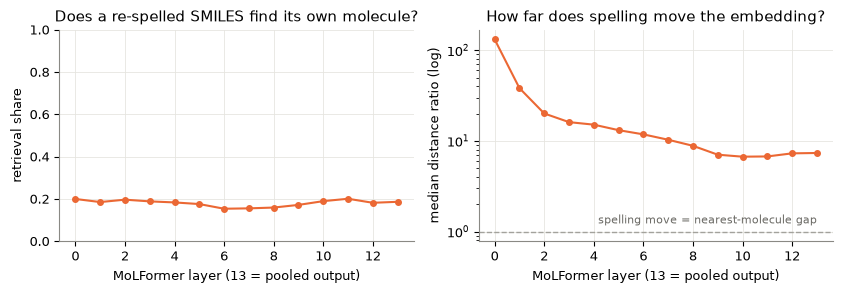

layer,hidden_0,hidden_1,hidden_2,hidden_3,hidden_4,hidden_5,hidden_6,hidden_7,hidden_8,hidden_9,hidden_10,hidden_11,hidden_12,pooler
retrieval_share,0.200,0.185,0.196,0.188,0.183,0.176,0.154,0.155,0.159,0.172,0.190,0.201,0.182,0.186
median_distance_ratio,132.133,38.273,20.110,16.134,15.128,13.156,11.824,10.316,8.842,7.055,6.707,6.747,7.299,7.366


In [5]:
inv = pd.read_csv(f"{R}/probes_invariance.csv")
inv["layer_no"] = range(len(inv))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3))
axes[0].plot(inv["layer_no"], inv["retrieval_share"], marker="o", ms=4, color=COLORS["molformer"])
axes[0].set(ylim=(0, 1), xlabel="MoLFormer layer (13 = pooled output)", ylabel="retrieval share",
            title="Does a re-spelled SMILES find its own molecule?")
axes[1].semilogy(inv["layer_no"], inv["median_distance_ratio"], marker="o", ms=4, color=COLORS["molformer"])
axes[1].axhline(1, color=GREY, ls="--", lw=1)
axes[1].text(13, 1.15, "spelling move = nearest-molecule gap", ha="right", va="bottom", color="#6b6a65", fontsize=8)
axes[1].set(xlabel="MoLFormer layer (13 = pooled output)", ylabel="median distance ratio (log)",
            title="How far does spelling move the embedding?")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_spelling_probe.png", dpi=150)
plt.show()
inv[["layer", "retrieval_share", "median_distance_ratio"]].round(3).set_index("layer").T

- **Re-spelling usually loses the molecule.** The retrieval share stays between 0.154 and 0.201 in every layer, so a re-spelled SMILES usually lands nearer another molecule's canonical embedding than its own.
- In layers 1–13, re-spelling moves the embedding 6.7 to 38 times further than the gap to the nearest other molecule (hidden_10: 6.707; hidden_1: 38.273). Layer 0, a context-free token average, reaches 132.
- **The frozen embeddings depend strongly on how a molecule is written.** MoLFormer was pretrained on canonical SMILES only, so this study gives it canonical SMILES throughout, a choice fixed in advance.

**Chain length.** Within the n-alkanes (C1–C44), 1-alcohols and 1-amines, do consecutive homologues stay distinguishable beyond eight carbons, where binary Morgan bits stop changing? The table shows the median distance between consecutive homologues up to and beyond C8, and the share of steps beyond C8 that leave the representation unchanged. MoLFormer is shown at layer 1, the layer the familiar-chemistry Ridge models chose (section 4), and at its pooled output.

In [6]:
chain = pd.read_csv(f"{R}/probes_chain_length.csv")
show = chain[chain["representation"].isin(["morgan_bits", "morgan_counts", "hidden_1", "pooler"])]
show.set_index(["series", "representation"])[["n", "chain_lengths", "median_step_distance_upto_C8",
                                              "median_step_distance_beyond_C8",
                                              "share_steps_beyond_C8_unchanged"]].round(4)

n chain_lengths  median_step_distance_upto_C8  \
series    representation                                                   
n-alkane  hidden_1        41        C1-C44                        0.0071   
          pooler          41        C1-C44                        0.0913   
          morgan_bits     41        C1-C44                        0.3239   
          morgan_counts   41        C1-C44                        0.1598   
1-alcohol hidden_1        19        C1-C24                        0.0058   
          pooler          19        C1-C24                        0.0525   
          morgan_bits     19        C1-C24                        0.1296   
          morgan_counts   19        C1-C24                        0.0785   
1-amine   hidden_1        17        C1-C18                        0.0093   
          pooler          17        C1-C18                        0.1858   
          morgan_bits     17        C1-C18                        0.2088   
          morgan_counts   17        C1-C18                        0.1404   

                          median_step_distance_beyond_C8  \
series    representation                                   
n-alkane  hidden_1                                0.0006   
          pooler                                  0.0075   
          morgan_bits                             0.0000   
          morgan_counts                           0.0000   
1-alcohol hidden_1                                0.0014   
          pooler                                  0.0318   
          morgan_bits                            -0.0000   
          morgan_counts                           0.0002   
1-amine   hidden_1                                0.0009   
          pooler                                  0.0144   
          morgan_bits                            -0.0000   
          morgan_counts                           0.0003   

                          share_steps_beyond_C8_unchanged  
series    representation                                   
n-alkane  hidden_1                                    0.0  
          pooler                                      0.0  
          morgan_bits                                 1.0  
          morgan_counts                               0.0  
1-alcohol hidden_1                                    0.0  
          pooler                                      0.0  
          morgan_bits                                 1.0  
          morgan_counts                               0.0  
1-amine   hidden_1                                    0.0  
          pooler                                      0.0  
          morgan_bits                                 1.0  
          morgan_counts                               0.0

- **Binary Morgan bits never change beyond C8** (share unchanged 1.0 in all three series). Morgan counts and both MoLFormer layers change at every step (share 0.0).
- **MoLFormer separates long chains, but compressed.** For n-alkanes at the pooled output, the median step falls from 0.0913 up to C8 to 0.0075 beyond it; at layer 1, from 0.0071 to 0.0006.
- Morgan counts also change at every step, but by tiny cosine distances beyond C8 (≤ 0.0003 in the table): one more CH₂ barely changes a vector dominated by the CH₂ count.

## 4. Familiar chemistry

Every representation was fitted with both regressors on the same 15 folds and the same inner folds. For MoLFormer, Ridge also chose the layer in the inner cross-validation, and XGBoost reused that layer. Each point below is one fold's test MAE. The dashed grey line is the feature study's ensemble (curated descriptors plus a family input, averaging Ridge, XGBoost and a neural network) on the same folds, for reference.

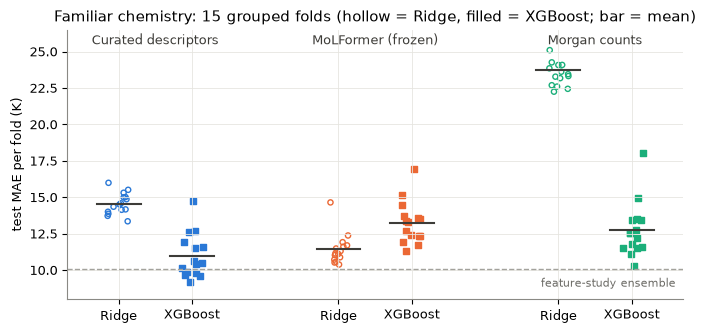

mean           std         best pipeline (folds)
regressor            ridge xgboost ridge xgboost                      
representation                                                        
Curated descriptors  14.56   11.00  0.72    1.51       {'xgboost': 15}
MoLFormer (frozen)   11.43   13.25  1.05    1.46         {'ridge': 15}
Morgan counts        23.71   12.75  1.29    1.86       {'xgboost': 15}

,mean,std
reference,,
"curated (log) + family ensemble (feature study, ungrouped inner CV)",10.08,1.06
molecular weight (Ridge),26.13,1.41
training mean,61.02,4.44


In [7]:
fam = preds[preds["regime"] == "familiar"]
fold_mae = fam.groupby(["representation", "regressor", "task"])["abs_err"].mean().reset_index()
ref_fold = refs[refs["regime"] == "familiar"].groupby(["reference", "task"])["abs_err"].mean()

fig, ax = plt.subplots(figsize=(7, 3.4))
rng = np.random.default_rng(0)
for i, r in enumerate(REPS):
    for j, (reg, marker) in enumerate([("ridge", "o"), ("xgboost", "s")]):
        v = fold_mae[(fold_mae["representation"] == r) & (fold_mae["regressor"] == reg)]["abs_err"]
        x = i * 3 + j
        ax.scatter(x + rng.uniform(-0.15, 0.15, len(v)), v, s=14, marker=marker, color=COLORS[r],
                   facecolors="none" if reg == "ridge" else COLORS[r], linewidths=1)
        ax.plot([x - 0.3, x + 0.3], [v.mean()] * 2, color="#3d3c38", lw=1.5)
ensemble = ref_fold.xs("curated (log) + family ensemble (feature study, ungrouped inner CV)").mean()
ax.axhline(ensemble, color=GREY, ls="--", lw=1)
ax.text(7.6, ensemble - 0.6, "feature-study ensemble", color="#6b6a65", fontsize=8, ha="right", va="top")
ax.set_xticks([0, 1, 3, 4, 6, 7], ["Ridge", "XGBoost"] * 3)
for i, r in enumerate(REPS):
    ax.text(i * 3 + 0.5, 25.5, NAMES[r], ha="center", color="#3d3c38", fontsize=9)
ax.set(ylabel="test MAE per fold (K)", ylim=(8, 26.5), xlim=(-0.7, 7.7),
       title="Familiar chemistry: 15 grouped folds (hollow = Ridge, filled = XGBoost; bar = mean)")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_familiar_folds.png", dpi=150)
plt.show()

table = fold_mae.groupby(["representation", "regressor"])["abs_err"].agg(["mean", "std"]).round(2).unstack()
chosen_reg = pd.read_csv(f"{F}/best_selection.csv").query("regime == 'familiar'")
table["best pipeline (folds)"] = chosen_reg.groupby("representation")["regressor"].agg(lambda s: s.value_counts().to_dict())
display(table.rename(index=NAMES))
ref_fold.groupby("reference").agg(["mean", "std"]).round(2)

- **XGBoost helps the conventional features but not the embeddings.** It beats Ridge for the curated descriptors (14.56 → 11.00 K) and Morgan counts (23.71 → 12.75 K), but not for MoLFormer (11.43 → 13.25 K). The inner cross-validation picked these same regressors in all 15 folds.
- **The best pipelines are close:** curated descriptors 11.00 ± 1.51 K, MoLFormer 11.43 ± 1.05 K, Morgan counts 12.75 ± 1.86 K. The gap between the first two (0.43 K) is well inside one fold SD.
- None beats the feature study's ensemble, at 10.08 ± 1.06 K. Molecular weight alone scores 26.13 K and the training mean 61.02 K.

**Which MoLFormer layer?** Ridge was fitted on every layer, each with its own penalty chosen in the inner cross-validation. The figure shows each layer's test MAE, averaged over the 15 folds; it is a diagnostic only, because the results above use the layer chosen in the inner cross-validation.

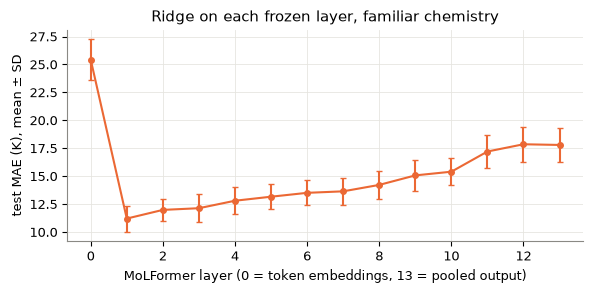

layer chosen in the inner CV, per fold: {1: 13, 2: 2}


layer,0,1,2,3,4,5,6,7,8,9,10,11,12,13
mean,25.43,11.21,11.99,12.14,12.81,13.17,13.51,13.65,14.22,15.08,15.41,17.21,17.86,17.80
std,1.82,1.17,1.01,1.26,1.19,1.13,1.12,1.21,1.28,1.36,1.19,1.45,1.56,1.54


In [8]:
probe = pd.read_csv(f"{F}/layer_probe.csv")
by_layer = probe.groupby("layer")["test_mae"].agg(["mean", "std"])
chosen = pd.read_csv(f"{F}/ridge_selection.csv").query("representation == 'molformer' and regime == 'familiar'")
fig, ax = plt.subplots(figsize=(6, 3))
ax.errorbar(by_layer.index, by_layer["mean"], yerr=by_layer["std"], marker="o", ms=4, capsize=2,
            color=COLORS["molformer"], lw=1.5)
ax.set(xlabel="MoLFormer layer (0 = token embeddings, 13 = pooled output)", ylabel="test MAE (K), mean ± SD",
       title="Ridge on each frozen layer, familiar chemistry")
fig.tight_layout()
fig.savefig(f"{IMG}/representation_layer_probe.png", dpi=150)
plt.show()
print("layer chosen in the inner CV, per fold:", chosen["layer"].astype(int).value_counts().sort_index().to_dict())
by_layer.round(2).T

- Test MAE is lowest at layer 1 (11.21 ± 1.17 K). It rises steadily to 17.86 ± 1.56 K at layer 12 and 17.80 ± 1.54 K for the pooled output. Layer 0, the context-free token average, is worst at 25.43 ± 1.82 K.
- **The inner cross-validation agreed:** it chose layer 1 in 13 folds and layer 2 in 2, without seeing any test data.
- One pass of context removes most of the error (25.43 → 11.21 K). Deeper layers, trained to predict masked tokens, are progressively less useful for boiling point.

## 5. Unseen functional groups

Each family is predicted by models trained on the other three, with hyperparameters chosen by leave-one-family-out inside the training families, so tuning rewards extrapolation. The bars show each representation's best pipeline; the grey tick is a Ridge model on molecular weight alone.

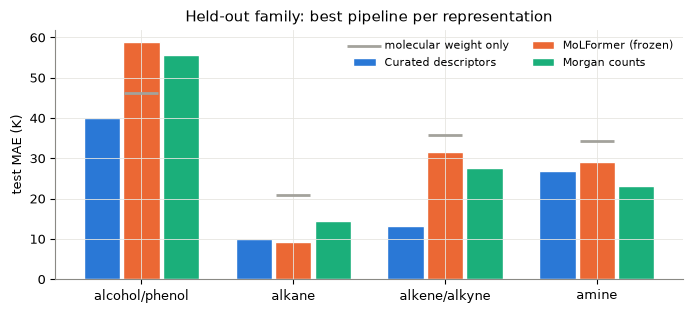

representation,Curated descriptors,MoLFormer (frozen),Morgan counts
task,,,
alcohol/phenol,40.0,59.0,55.8
alkane,10.0,9.2,14.4
alkene/alkyne,13.3,31.5,27.7
amine,26.8,29.0,23.2
mean over families,22.5,32.2,30.3


best-pipeline regressor: {'curated': 'xgboost', 'molformer': 'ridge', 'morgan': 'xgboost'}


In [9]:
hold = best[best["regime"] == "holdout"].groupby(["task", "representation"])["abs_err"].mean().unstack()[REPS]
mw = refs[(refs["regime"] == "holdout") & (refs["reference"] == "molecular weight (Ridge)")].groupby("task")["abs_err"].mean()
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(hold))
for k, r in enumerate(REPS):
    ax.bar(x + (k - 1) * 0.26, hold[r], width=0.24, color=COLORS[r], label=NAMES[r], edgecolor="white", linewidth=1)
ax.scatter(x, mw.loc[hold.index], marker="_", s=600, color=GREY, linewidths=2, label="molecular weight only", zorder=3)
ax.set_xticks(x, hold.index)
ax.set(ylabel="test MAE (K)", title="Held-out family: best pipeline per representation")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_family_holdout.png", dpi=150)
plt.show()
regressors = best[best["regime"] == "holdout"].groupby("representation")["regressor"].first()
out = hold.round(1).rename(columns=NAMES)
out.loc["mean over families"] = hold.mean().round(1).rename(NAMES)
display(out)
print("best-pipeline regressor:", regressors.to_dict())

- **Averaged over the four families, the curated descriptors lead:** 22.5 K, against 30.3 K for Morgan counts and 32.2 K for MoLFormer.
- MoLFormer matches the descriptors on alkanes (9.2 vs 10.0 K) but is far worse on alcohols/phenols (59.0 vs 40.0 K) and alkenes/alkynes (31.5 vs 13.3 K). On alcohols/phenols it's even worse than molecular weight alone (grey tick).
- Morgan counts do best on amines (23.2 K, vs 26.8 K for the descriptors and 29.0 K for MoLFormer).
- **The expectation that Morgan counts would fail worst on unseen families isn't borne out.** With XGBoost as its best pipeline, Morgan isn't the worst on average; MoLFormer is.

## 6. Unseen elements and rings

The NIST compounds lie far from the training data: none of the 1,250 training molecules has a ring or a halogen. Each panel plots a representation's best-pipeline predictions against the NIST label, with the grey line marking a perfect prediction.

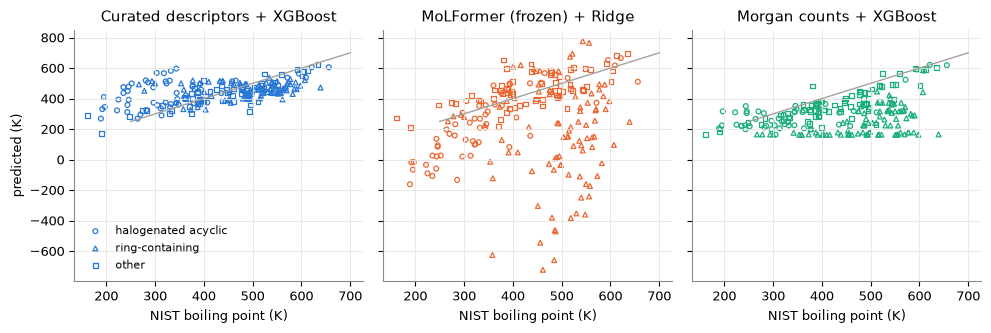

representation,Curated descriptors,MoLFormer (frozen),Morgan counts
subgroup,,,
halogenated acyclic,105.5,146.2,72.3
other,43.9,78.3,72.3
ring-containing,78.3,389.1,254.4
all 211,74.7,224.8,147.4
min prediction (K),171.7,-722.4,161.9


training-mean reference MAE: 94.0 K


,name,subgroup,y_true,y_pred
5183,Iodobenzene,ring-containing,461.6,-722.4
5205,2-Iodotoluene,ring-containing,484.7,-658.6
5181,4-Fluoroiodobenzene,ring-containing,456.2,-544.7
5206,Fluorobenzene,ring-containing,358.0,-625.1
5194,4-Iodotoluene,ring-containing,487.6,-470.1


In [10]:
nb = best[best["regime"] == "nist"].assign(subgroup=lambda d: d["key"].map(subgroup))
markers = {"halogenated acyclic": "o", "ring-containing": "^", "other": "s"}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharey=True)
for ax, r in zip(axes, REPS):
    d = nb[nb["representation"] == r]
    for g, m in markers.items():
        s = d[d["subgroup"] == g]
        ax.scatter(s["y_true"], s["y_pred"], s=12, marker=m, facecolors="none", edgecolors=COLORS[r], linewidths=0.9,
                   label=g)
    ax.plot([250, 700], [250, 700], color=GREY, lw=1)
    ax.set(title=f"{NAMES[r]} + {REG[d['regressor'].iloc[0]]}", xlabel="NIST boiling point (K)")
axes[0].set_ylabel("predicted (K)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(f"{IMG}/representation_nist.png", dpi=150)
plt.show()

table = nb.groupby(["subgroup", "representation"])["abs_err"].mean().unstack()[REPS]
table.loc["all 211"] = nb.groupby("representation")["abs_err"].mean()[REPS]
table.loc["min prediction (K)"] = nb.groupby("representation")["y_pred"].min()[REPS]
mean_ref = refs[(refs["regime"] == "nist") & (refs["reference"] == "training mean")]["abs_err"].mean()
display(table.round(1).rename(columns=NAMES))
print(f"training-mean reference MAE: {mean_ref:.1f} K")
nb[nb["representation"] == "molformer"].nlargest(5, "abs_err").assign(
    name=lambda d: d["key"].map(dict(zip("nist:" + nist.index.astype(str), nist["cmpdname"]))))[
    ["name", "subgroup", "y_true", "y_pred"]].round(1)

- **Only the descriptors beat simply predicting the training mean** (74.7 vs 94.0 K). MoLFormer reaches 224.8 K and Morgan counts 147.4 K.
- MoLFormer's failure is concentrated on ring compounds (389.1 K MAE). It predicts physically impossible negative temperatures, down to −722.4 K for iodobenzene: a linear model extrapolating far outside training data that has no rings or iodine.
- Morgan counts with XGBoost can't extrapolate either: their predictions never go below 161.9 K, and ring compounds pile up near that floor (254.4 K MAE). On halogenated acyclic compounds, though, Morgan counts are best (72.3 K, vs 105.5 K for the descriptors and 146.2 K for MoLFormer).

**Is it the regressor?** The inner cross-validation chose Ridge for MoLFormer everywhere, because it beat XGBoost on familiar chemistry. Trees can't predict outside the range of the training labels, so the controlled XGBoost results (not the best pipeline, shown for comparison) separate the representation from the linear extrapolation:

In [11]:
pn = preds[preds["regime"] == "nist"].assign(subgroup=lambda d: d["key"].map(subgroup))
pn.groupby(["subgroup", "representation", "regressor"])["abs_err"].mean().unstack(["representation", "regressor"])[REPS].round(1)

representation      curated         molformer         morgan        
regressor             ridge xgboost     ridge xgboost  ridge xgboost
subgroup                                                            
halogenated acyclic    69.3   105.5     146.2   115.3  114.2    72.3
other                  58.3    43.9      78.3    64.5   71.0    72.3
ring-containing        91.8    78.3     389.1   109.7  108.8   254.4

- **Most of MoLFormer's failure is the linear extrapolation.** With XGBoost, its ring-compound error falls from 389.1 to 109.7 K. It still trails the descriptors' best on rings (78.3 K, XGBoost), and on halogenated acyclic compounds (115.3 vs 69.3 K, descriptors with Ridge).
- The descriptors do better with Ridge than XGBoost on halogenated acyclic compounds (69.3 vs 105.5 K). **A pipeline chosen on familiar data isn't necessarily the best one out of distribution,** a limitation of selecting it by inner cross-validation.
- No combination predicts the NIST compounds well. The best subgroup errors are 43.9–78.3 K, against label noise of about half a kelvin (section 1).

## 7. Provisional confirmatory comparisons C1–C3

Each estimate is MAE(MoLFormer) − MAE(curated descriptors), best pipelines on both sides; positive means MoLFormer is worse.
- **C1** uses the corrected resampled t-test of Nadeau & Bengio (2003, *Machine Learning* 52). Repeated cross-validation folds share most of their training data, so it widens the plain t-test's variance by (1/15 + n_test/n_train).
- **C2 and C3** average the per-family or per-subgroup differences with equal weight. Their 95% confidence intervals (CI) come from 10,000 bootstrap resamples of molecules within each family or subgroup.

The p-values are raw. Holm's correction (Holm, 1979, *Scandinavian Journal of Statistics* 6) needs C4 and C5 as well, but it can multiply a p-value by at most the number of tests, 5. The last column shows that bound.

In [12]:
conf = pd.read_csv(f"{F}/confirmatory_provisional.csv")
# A bootstrap p of 0 means none of the 10,000 resamples crossed zero: p < 2/10,000
bootstrap = conf["comparison"].isin(["C2", "C3"])
conf["p (raw)"] = [("< 0.0002" if b and p == 0 else f"{p:.3f}") for p, b in zip(conf["p_raw"], bootstrap)]
conf["Holm bound (5 × p)"] = [("< 0.001" if b and p == 0 else f"{min(1, 5 * p):.3f}")
                              for p, b in zip(conf["p_raw"], bootstrap)]
conf["|estimate| ≥ 1.0 K"] = conf["estimate"].abs() >= 1.0
show = conf[["comparison", "regime", "estimate", "se", "ci_low", "ci_high", "p (raw)", "Holm bound (5 × p)",
             "|estimate| ≥ 1.0 K"]].round(3).set_index("comparison")
display(show)
pd.DataFrame({c: json.loads(s) for c, s in conf.set_index("comparison")["per_stratum"].dropna().items()}).round(2)

,regime,estimate,se,ci_low,ci_high,p (raw),Holm bound (5 × p),|estimate| ≥ 1.0 K
comparison,,,,,,,,
C1,familiar,0.432,0.634,NaN,NaN,0.506,1.000,False
C2,holdout,9.667,NaN,8.398,10.946,< 0.0002,< 0.001,True
C3,nist,128.694,NaN,105.964,152.702,< 0.0002,< 0.001,True


,C2,C3
alcohol/phenol,18.97,NaN
alkane,-0.74,NaN
alkene/alkyne,18.17,NaN
amine,2.27,NaN
halogenated acyclic,NaN,40.78
other,NaN,34.42
ring-containing,NaN,310.88


- **C1 (familiar):** MoLFormer is 0.43 K worse, SE 0.63, p = 0.506. There's no detectable difference, and the estimate is below the 1.0 K minimum anyway.
- **C2 (unseen families):** 9.67 K worse (95% CI 8.40 to 10.95). This is driven by alcohols/phenols (+18.97) and alkenes/alkynes (+18.17); the difference is near zero for alkanes (−0.74) and small for amines (+2.27).
- **C3 (NIST):** 128.7 K worse (95% CI 106.0 to 152.7), driven by ring-containing compounds (+310.88).
- **The outcome is already fixed.** Even at Holm's largest possible inflation, C2 and C3 stay below 0.001 and exceed 1.0 K, so they will count as findings whatever C4 and C5 show. C1 cannot become one.

## 8. Key findings so far

1. **Familiar chemistry: frozen embeddings are on par with physically motivated descriptors.** MoLFormer + Ridge scores 11.43 K and curated descriptors + XGBoost 11.00 K (C1: +0.43 K, p = 0.506). Both trail the feature-study ensemble (10.08 K).
2. **Unfamiliar chemistry: frozen embeddings generalise *worse*, not better.** MoLFormer is +9.67 K on unseen families (95% CI 8.40 to 10.95) and +128.7 K on the NIST set (95% CI 106.0 to 152.7). Pretraining on unlabelled structures didn't carry over through a frozen readout, contrary to the hope that it would help most on unfamiliar chemistry.
3. **Linear readouts of frozen embeddings extrapolate without bound outside the training data,** down to −722.4 K for iodobenzene. Choosing the pipeline by inner cross-validation on familiar data can't reveal this. With XGBoost, MoLFormer's ring-compound error drops from 389.1 to 109.7 K, but it still trails the descriptors.
4. **What the embeddings carry:** the useful information sits in an early layer (layer 1: 11.21 K; pooled output: 17.80 K). The embeddings depend strongly on how a SMILES is written (retrieval share ≤ 0.201), and they separate long chains, unlike binary Morgan bits.

**Next:** Step 4 fine-tunes MoLFormer (C5), testing whether adapting the encoder, rather than freezing it, changes this picture. Steps 5–6 add prediction intervals and learning curves (C4). Holm's correction and the final decisions follow once C4 and C5 exist.